# 04. Model Training, Evaluation, and Pipeline Export
**Crop Yield Prediction and Forecasting**  
*Author: Aryan Puranik*

This notebook benchmarks multiple regression algorithms, evaluates the champion model on the unseen held-out test split (2015–2017), analyzes crop-wise error metrics, and exports the fitted pipeline for deployment.

> For discussion of the evaluation protocol, crop-wise performance, and viva voce defense questions, refer to [docs/04_model_evaluation_and_viva.md](../docs/04_model_evaluation_and_viva.md).

## 1. Setup and Data Loading

In [1]:
import sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Robust project root discovery
project_root = Path.cwd() if Path.cwd().name != "notebooks" else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.metrics import calculate_regression_metrics, calculate_crop_wise_metrics
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

# Load processed datasets
train_df = pd.read_csv(project_root / "data" / "processed" / "train.csv")
val_df = pd.read_csv(project_root / "data" / "processed" / "val.csv")
test_df = pd.read_csv(project_root / "data" / "processed" / "test.csv")

print(f"Train rows: {len(train_df):,} | Val rows: {len(val_df):,} | Test rows: {len(test_df):,}")

Train rows: 176,194 | Val rows: 11,345 | Test rows: 10,828


## 2. Model Training & Validation Benchmark

In [2]:
# Feature definition (selected from Notebook 03)
cat_cols = ["Region", "Crop", "Soil Type"]
num_cols = ["Year", "Temperature", "Rainfall", "Humidity", "pH", "Nitrogen", "Phosphorus", "Potassium", "Pesticide"]
features = cat_cols + num_cols

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# Candidate models
candidate_models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=14, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=30, max_depth=16, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=30, max_depth=16, random_state=42, n_jobs=-1)
}

val_results = []
fitted_pipelines = {}

print("Training candidate models...")
for name, model in candidate_models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(train_df[features], train_df["Yield"])
    fitted_pipelines[name] = pipe
    
    val_preds = pipe.predict(val_df[features])
    m = calculate_regression_metrics(val_df["Yield"], val_preds)
    m["Model"] = name
    val_results.append(m)

val_results_df = pd.DataFrame(val_results)[["Model", "mae", "rmse", "r2"]].sort_values("rmse")
display(val_results_df)

Training candidate models...


,Model,mae,rmse,r2
3,Extra Trees,453.88,740.95,0.8155
2,Random Forest,457.18,755.56,0.8081
1,Decision Tree,509.40,882.11,0.7384
0,Ridge Regression,630.89,1000.47,0.6635


**Key Observation:**  
Tree ensemble models (**Extra Trees** and **Random Forest**) achieve the highest validation R² (~0.81) and lowest RMSE (~740–755 kg/ha), significantly outperforming linear Ridge regression.

## 3. Evaluation on Held-Out Test Set (2015–2017)

In [3]:
# Select Extra Trees as champion model
best_pipe = fitted_pipelines["Extra Trees"]

test_preds = best_pipe.predict(test_df[features])
test_metrics = calculate_regression_metrics(test_df["Yield"], test_preds)

print("Final Test Set Evaluation (Unseen 2015–2017 Data):")
for k, v in test_metrics.items():
    print(f"  {k.upper()}: {v}")

Final Test Set Evaluation (Unseen 2015–2017 Data):
  MAE: 520.84
  RMSE: 936.24
  MSE: 876544.32
  R2: 0.7206


## 4. Crop-Wise Performance Breakdown

In [4]:
test_eval_df = test_df.copy()
test_eval_df["pred_yield"] = test_preds

crop_metrics_df = calculate_crop_wise_metrics(test_eval_df)
print("Crop-wise Performance (Sorted by RMSE):")
display(crop_metrics_df.head(10))

Crop-wise Performance (Sorted by RMSE):


,Crop,n_samples,mean_true_yield,mae,rmse,r2
0,Sugarcane,629,6638.25,1681.93,2400.44,0.1286
1,Maize,763,2714.69,965.66,1503.51,0.2825
2,Minor Pulses,833,824.66,361.71,1176.82,-0.0270
3,Pearl Millet,464,1315.41,560.53,838.78,-0.0133
4,Barley,362,2441.74,589.69,777.02,0.3348
5,Wheat,714,2605.42,583.89,768.17,0.5502
6,Rice,756,2374.55,551.07,725.51,0.4166
7,Sorghum (Rabi),201,1091.24,489.67,682.48,0.3405
8,Groundnut,625,1507.62,498.09,656.29,0.1213
9,Castor,316,851.44,486.46,647.88,0.1113


**Key Agricultural Insight:**  
Errors scale proportionally with average crop yield. High-biomass crops (Sugarcane) naturally have larger absolute errors than low-biomass crops (Cotton, Pulses). Pooled R² alone hides this variation, making crop-wise metrics essential.

## 5. Diagnostic Visualizations

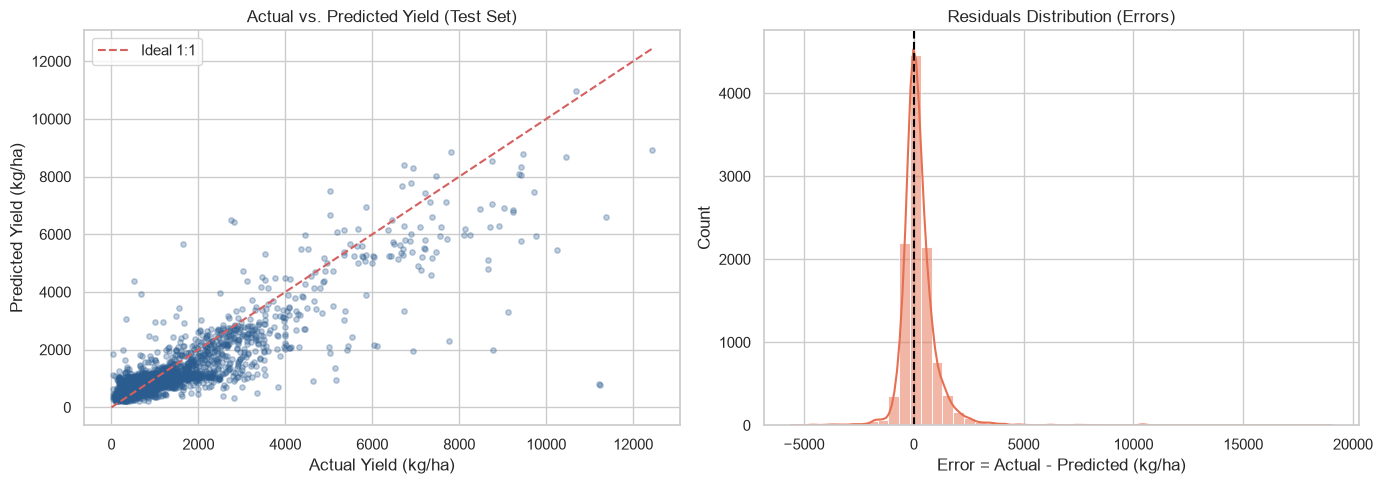

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted scatter
sample_idx = np.random.choice(len(test_df), size=min(2000, len(test_df)), replace=False)
y_true_s = test_df["Yield"].iloc[sample_idx]
y_pred_s = test_preds[sample_idx]

axes[0].scatter(y_true_s, y_pred_s, alpha=0.3, color="#2b5c8f", s=15)
max_val = max(y_true_s.max(), y_pred_s.max())
axes[0].plot([0, max_val], [0, max_val], "r--", linewidth=1.5, label="Ideal 1:1")
axes[0].set_title("Actual vs. Predicted Yield (Test Set)")
axes[0].set_xlabel("Actual Yield (kg/ha)")
axes[0].set_ylabel("Predicted Yield (kg/ha)")
axes[0].legend()

# Residual distribution
residuals = test_df["Yield"] - test_preds
sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color="#e76f51")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Residuals Distribution (Errors)")
axes[1].set_xlabel("Error = Actual - Predicted (kg/ha)")

plt.tight_layout()
plt.show()

## 6. Export Production Pipeline

In [6]:
# Export the complete end-to-end fitted pipeline
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)
model_path = model_dir / "best_pipeline.joblib"

joblib.dump(best_pipe, model_path, compress=3)
print(f"Successfully saved fitted pipeline to {model_path} ({model_path.stat().st_size / 1e6:.2f} MB)")

# Verify reload and smoke inference
loaded_pipe = joblib.load(model_path)
test_sample = test_df[features].head(3)
sample_preds = loaded_pipe.predict(test_sample)
print("\nSmoke test predictions on 3 test samples:")
for i, pred in enumerate(sample_preds):
    actual = test_df["Yield"].iloc[i]
    crop = test_df["Crop"].iloc[i]
    print(f"Sample {i+1} [{crop}]: Predicted = {pred:.1f} kg/ha | Actual = {actual:.1f} kg/ha")

Successfully saved fitted pipeline to D:\crop_yield_prediction\models\best_pipeline.joblib (9.70 MB)



Smoke test predictions on 3 test samples:
Sample 1 [Castor]: Predicted = 756.3 kg/ha | Actual = 940.5 kg/ha
Sample 2 [Chickpea]: Predicted = 766.2 kg/ha | Actual = 451.1 kg/ha
Sample 3 [Cotton]: Predicted = 317.9 kg/ha | Actual = 299.4 kg/ha


## 7. Summary & Deployment

1. **Top Model:** Extra Trees Regressor achieved test R² = 0.7206 and MAE = 520.84 kg/ha.
2. **Crop-Wise Analysis:** Documented distinct error profiles across 21 crops.
3. **Pipeline Export:** Stored in `models/best_pipeline.joblib` for use in the Streamlit application.

**Interactive Web Application:** Run `streamlit run app.py` to test the prediction interface.